# 03trajectories: where the air went, and where it came from

Part A of PF5. Air parcels are moved with the ERA5 winds from `01event`, so no new downloads are needed.

| Section | Question |
|---|---|
| 2 | The trajectory model (small and transparent) |
| 3 | **Forward from the fires**: of the air leaving fire areas in Sumatra, Kalimantan and eastern Indonesia, how much reached the Pacific corridor and Choi-wan? This puts numbers on the "inward" geography: eastern Indonesia feeds the storm, Sumatra and Kalimantan do not. |
| 4 | **Backward from Kuala Lumpur and Singapore**: over which fire region did their air pass in the 72 hours before arriving? |

**Method in one paragraph.** Each parcel moves with the horizontal wind on one level: the 10 m wind (the air near the surface, which is where a typhoon draws its inflow), 850 hPa (about 1.5 km up, where much of the smoke travels) and 700 hPa (about 3 km, as a check). Winds are interpolated in space (bilinear) and time (linear between the ERA5 steps: hourly at 10 m, 3-hourly aloft), and positions are stepped every 30 minutes with a second-order (Heun) scheme. These are **isobaric trajectories**: they ignore rising and sinking air, so they show the transport pattern rather than the path of every particle. Results are reported as shares of many parcels, not single lines. A full model such as NOAA HYSPLIT would add vertical motion and mixing; that is a possible later check.

## Section 0: settings

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw" / "event"
OUT_DIR = PROJECT_DIR / "data" / "processed" / "event"
FIG_DIR = OUT_DIR / "figures"
COAST_DIR = PROJECT_DIR / "data" / "raw" / "naturalearth"

LEVELS = ["10 m", "850 hPa", "700 hPa"]  # <- "10 m" = near-surface wind (hourly); hPa levels are 3-hourly and must be in the 01event download
DT_MIN = 30  # <- time step in minutes

# Forward runs from fire areas
FWD_START = "2026-09-28 00:00"  # <- first release (start of the ERA5 data)
FWD_END = "2026-10-04 18:00"  # <- last release
FWD_EVERY_H = 6  # <- release every n hours
FWD_HOURS = 144  # <- how long each parcel is followed (6 days; parcels stop at the end of the ERA5 data)
FIRE_CELL_DEG = 0.5  # <- hotspots are counted in cells of this size
FIRE_MIN = 10  # <- a cell is a "fire cell" on a day with at least this many VIIRS hotspots
NEAR_STORM_KM = 500  # <- a parcel "reached Choi-wan" if it came this close to the storm centre
OUTER_STORM_KM = 1000  # <- a parcel "reached the outer circulation" if it came this close

# Backward runs from cities
CITIES = {"Kuala Lumpur": (3.14, 101.69), "Singapore": (1.35, 103.82)}  # <- (lat, lon)
BWD_START = "2026-10-01 00:00"  # <- first arrival time (ERA5 starts 28 Sep, so 72 h back fits)
BWD_END = "2026-10-07 21:00"  # <- last arrival time
BWD_EVERY_H = 3  # <- an arrival every n hours
BWD_HOURS = 72  # <- how far back each parcel is followed
BWD_SPREAD = 0.25  # <- 5 parcels per arrival: the city and 4 points this many degrees around it

# Fire regions: Indonesian land (Natural Earth country borders) inside these boxes (west, east, south, north)
REGIONS = {}
REGIONS["Sumatra"] = (95.0, 106.0, -6.0, 4.0)  # <-
REGIONS["Kalimantan"] = (108.0, 118.5, -4.5, 2.0)  # <-
REGIONS["Eastern Indonesia"] = (119.0, 141.0, -9.0, 2.0)  # <-
CORRIDOR = (128.0, 150.0, 3.0, 18.0)  # <- Pacific corridor
MAP_EXTENT = (90.0, 160.0, -15.0, 45.0)  # <-

# VISUAL
REGION_COLORS = {"Sumatra": "#2a78d6", "Kalimantan": "#eb6834", "Eastern Indonesia": "#1baf7a", "No fire region": "#a8a7a2"}  # <-
LINES_PER_REGION = 150  # <- VISUAL: trajectories drawn per region on the forward map (all are counted)
MAP_LEVEL = "850 hPa"  # <- VISUAL: level shown on the maps (all levels are in the tables and CSV files)

## Section 1: imports and data

In [2]:
import json
import numpy as np
import pandas as pd
import xarray as xr
import requests
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath

FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.facecolor"] = "#fcfcfb"
plt.rcParams["axes.facecolor"] = "#fcfcfb"
plt.rcParams["axes.edgecolor"] = "#a8a7a2"
plt.rcParams["font.size"] = 10
R_EARTH = 6371.0

era = xr.concat([xr.open_dataset(f) for f in sorted(RAW_DIR.glob("era5_levels_*.nc"))], dim="valid_time").sortby("latitude")
sfc = xr.concat([xr.open_dataset(f) for f in sorted(RAW_DIR.glob("era5_single_*instant*.nc"))], dim="valid_time").sortby("latitude")
E_LAT = era.latitude.values
E_LON = era.longitude.values
T0 = pd.Timestamp(era.valid_time.values[0])
U = {}
V = {}
E_HOURS = {}
for lev in LEVELS:
    if lev == "10 m":
        U[lev] = sfc["u10"].values
        V[lev] = sfc["v10"].values
        E_HOURS[lev] = (pd.to_datetime(sfc.valid_time.values) - T0).total_seconds().values / 3600
    else:
        U[lev] = era["u"].sel(pressure_level=int(lev.split()[0])).values
        V[lev] = era["v"].sel(pressure_level=int(lev.split()[0])).values
        E_HOURS[lev] = (pd.to_datetime(era.valid_time.values) - T0).total_seconds().values / 3600
    print(f"ERA5 wind {lev}: {U[lev].shape[0]} steps, hours {E_HOURS[lev][0]:.0f} to {E_HOURS[lev][-1]:.0f} after {T0}")

fires = pd.read_csv(RAW_DIR / "firms_event.csv", low_memory=False)
fires = fires[fires["source"].str.startswith("VIIRS") & (fires["confidence"] != "l")].copy()
fires["date"] = pd.to_datetime(fires["acq_date"])

track = pd.read_csv(RAW_DIR / "choiwan_track.csv")
track["time"] = pd.to_datetime(track["ISO_TIME"])
track_hours = (track["time"] - T0).dt.total_seconds().values / 3600
print("Track:", track["time"].iloc[0], "to", track["time"].iloc[-1])


def storm_at(hours):
    # Storm centre at given hours since T0 (NaN outside the track's lifetime)
    lat = np.interp(hours, track_hours, track["LAT"].values, left=np.nan, right=np.nan)
    lon = np.interp(hours, track_hours, track["LON"].values, left=np.nan, right=np.nan)
    return lat, lon


def km_between(lat1, lon1, lat2, lon2):
    p1 = np.deg2rad(lat1)
    p2 = np.deg2rad(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.deg2rad(lon2 - lon1) / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(a))


def in_box(lat, lon, box):
    return (lon >= box[0]) & (lon <= box[1]) & (lat >= box[2]) & (lat <= box[3])


def load_lines(path):
    lines = []
    for feat in json.loads(path.read_text(encoding="utf8"))["features"]:
        geom = feat["geometry"]
        parts = geom["coordinates"] if geom["type"] == "MultiLineString" else [geom["coordinates"]]
        lines += [np.array(p) for p in parts]
    return lines


COAST = load_lines(COAST_DIR / "ne_50m_coastline.geojson")

# Indonesia's land area from Natural Earth (downloaded once, about 3 MB), used so that fire cells in
# Malaysia (Sarawak, Sabah, the Malay Peninsula), Brunei, Timor-Leste or Papua New Guinea are not counted
COUNTRIES_FILE = COAST_DIR / "ne_50m_admin_0_countries.geojson"
if not COUNTRIES_FILE.exists():
    r = requests.get("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson", timeout=120)
    print("Country borders download, HTTP status:", r.status_code)
    COUNTRIES_FILE.write_bytes(r.content)
indo = [f for f in json.loads(COUNTRIES_FILE.read_text(encoding="utf8"))["features"] if f["properties"]["NAME"] == "Indonesia"][0]["geometry"]
indo_polys = indo["coordinates"] if indo["type"] == "MultiPolygon" else [indo["coordinates"]]
INDO_PATHS = [MplPath(np.array(p[0])) for p in indo_polys]


def in_indonesia(lat, lon):
    pts = np.column_stack([np.asarray(lon), np.asarray(lat)])
    inside = np.zeros(len(pts), dtype=bool)
    for path in INDO_PATHS:
        inside |= path.contains_points(pts)
    return inside


def draw_base(ax, extent=MAP_EXTENT):
    for line in COAST:
        ax.plot(line[:, 0], line[:, 1], color="#52514e", lw=0.5)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.tick_params(labelsize=8, colors="#52514e")

ERA5 wind 10 m: 240 steps, hours 0 to 239 after 2026-09-28 00:00:00
ERA5 wind 850 hPa: 80 steps, hours 0 to 237 after 2026-09-28 00:00:00
ERA5 wind 700 hPa: 80 steps, hours 0 to 237 after 2026-09-28 00:00:00
Track: 2026-09-30 00:00:00 to 2026-10-07 06:00:00
Country borders download, HTTP status: 200


## Section 2: the trajectory model

In [3]:
def wind_at(lev, hours, lat, lon):
    # Bilinear in space, linear in time; returns NaN outside the ERA5 box or time range
    u_out = np.full(lat.shape, np.nan)
    v_out = np.full(lat.shape, np.nan)
    eh = E_HOURS[lev]
    ok = (hours >= eh[0]) & (hours <= eh[-1]) & (lat >= E_LAT[0]) & (lat <= E_LAT[-1]) & (lon >= E_LON[0]) & (lon <= E_LON[-1])
    if not ok.any():
        return u_out, v_out
    h = hours[ok]
    y = lat[ok]
    x = lon[ok]
    k = np.clip(np.searchsorted(eh, h) - 1, 0, len(eh) - 2)
    ft = (h - eh[k]) / (eh[k + 1] - eh[k])
    j = np.clip(np.searchsorted(E_LAT, y) - 1, 0, len(E_LAT) - 2)
    i = np.clip(np.searchsorted(E_LON, x) - 1, 0, len(E_LON) - 2)
    fy = (y - E_LAT[j]) / (E_LAT[j + 1] - E_LAT[j])
    fx = (x - E_LON[i]) / (E_LON[i + 1] - E_LON[i])
    for field, out in [(U[lev], u_out), (V[lev], v_out)]:
        vals = []
        for kk in [k, k + 1]:
            a = field[kk, j, i] * (1 - fx) + field[kk, j, i + 1] * fx
            b = field[kk, j + 1, i] * (1 - fx) + field[kk, j + 1, i + 1] * fx
            vals.append(a * (1 - fy) + b * fy)
        out[ok] = vals[0] * (1 - ft) + vals[1] * ft
    return u_out, v_out


def move(lat, lon, u, v, dt_s):
    # Move by wind (m/s) for dt_s seconds on the sphere
    dlat = np.rad2deg(v * dt_s / (R_EARTH * 1000))
    dlon = np.rad2deg(u * dt_s / (R_EARTH * 1000 * np.cos(np.deg2rad(lat))))
    return lat + dlat, lon + dlon


def run_trajectories(lev, start_hours, lat0, lon0, n_hours, direction=1):
    # Heun (predictor-corrector) integration; direction 1 = forward, -1 = backward
    n_steps = int(n_hours * 60 / DT_MIN)
    dt_s = DT_MIN * 60 * direction
    lat = np.array(lat0, dtype=float)
    lon = np.array(lon0, dtype=float)
    hrs = np.array(start_hours, dtype=float)
    out_lat = np.full((n_steps + 1, len(lat)), np.nan)
    out_lon = np.full((n_steps + 1, len(lat)), np.nan)
    out_lat[0] = lat
    out_lon[0] = lon
    for n in range(n_steps):
        u1, v1 = wind_at(lev, hrs, lat, lon)
        lat_p, lon_p = move(lat, lon, u1, v1, dt_s)
        hrs_next = hrs + dt_s / 3600
        u2, v2 = wind_at(lev, hrs_next, lat_p, lon_p)
        lat, lon = move(lat, lon, 0.5 * (u1 + u2), 0.5 * (v1 + v2), dt_s)
        hrs = hrs_next
        out_lat[n + 1] = lat
        out_lon[n + 1] = lon
    step_hours = np.arange(n_steps + 1) * DT_MIN / 60 * direction
    return out_lat, out_lon, step_hours


# Sanity check: a parcel in a steady 10 m/s westerly wind at the equator should move about 864 km in a day
lat_t, lon_t = move(np.array([0.0]), np.array([120.0]), np.array([10.0]), np.array([0.0]), 86400)
print(f"Check: 10 m/s for 24 h at the equator moves {km_between(0, 120, lat_t[0], lon_t[0]):.0f} km (expected 864)")

Check: 10 m/s for 24 h at the equator moves 864 km (expected 864)


## Section 3: forward from the fires

Fire cells are 0.5 degree squares with at least the set number of VIIRS hotspots on a day. A parcel is released from the centre of every fire cell in the three regions at every release time (using that day's fire cells), and followed for 72 hours or until it leaves the ERA5 box.

In [4]:
releases = pd.date_range(FWD_START, FWD_END, freq=f"{FWD_EVERY_H}h")
# Keep hotspots on Indonesian land inside the region boxes, then label them by region
fires["region"] = None
for name, box in REGIONS.items():
    fires.loc[in_box(fires["latitude"], fires["longitude"], box), "region"] = name
fires = fires.dropna(subset=["region"]).copy()
fires = fires[in_indonesia(fires["latitude"].values, fires["longitude"].values)].copy()
print("VIIRS hotspots on Indonesian land in the three regions:", len(fires))
fires["cell_lat"] = (np.floor(fires["latitude"] / FIRE_CELL_DEG) + 0.5) * FIRE_CELL_DEG
fires["cell_lon"] = (np.floor(fires["longitude"] / FIRE_CELL_DEG) + 0.5) * FIRE_CELL_DEG
cells = fires.groupby(["date", "cell_lat", "cell_lon"]).agg(hotspots=("region", "size"), region=("region", "first")).reset_index()
cells = cells[cells["hotspots"] >= FIRE_MIN]
FIRE_CELL_REGION = cells.drop_duplicates(["cell_lat", "cell_lon"]).set_index(["cell_lat", "cell_lon"])["region"].to_dict()
print("Distinct fire cells over the window:", len(FIRE_CELL_REGION))
print("Fire cells per day and region:")
print(cells.groupby(["date", "region"]).size().unstack("region").fillna(0).astype(int))

seed_rows = []
for t in releases:
    day = cells[cells["date"] == t.normalize()]
    seed_rows.append(pd.DataFrame({"release": t, "region": day["region"].values, "lat0": day["cell_lat"].values, "lon0": day["cell_lon"].values, "hotspots": day["hotspots"].values}))
seeds = pd.concat(seed_rows, ignore_index=True)
seeds["start_h"] = (seeds["release"] - T0).dt.total_seconds() / 3600
print("Parcels per level:", len(seeds))

fwd = {}
fwd_rows = []
for lev in LEVELS:
    lat, lon, sh = run_trajectories(lev, seeds["start_h"].values, seeds["lat0"].values, seeds["lon0"].values, FWD_HOURS, 1)
    abs_h = seeds["start_h"].values[None, :] + sh[:, None]
    s_lat, s_lon = storm_at(abs_h)
    dist = km_between(lat, lon, s_lat, s_lon)
    min_dist = np.nanmin(np.where(np.isnan(dist), np.inf, dist), axis=0)
    in_corr = in_box(lat, lon, CORRIDOR)
    res = seeds.copy()
    res["level"] = lev
    res["reached_corridor"] = in_corr.any(axis=0)
    res["min_km_to_storm"] = np.where(np.isinf(min_dist), np.nan, min_dist)
    res["reached_storm"] = res["min_km_to_storm"] <= NEAR_STORM_KM
    res["reached_outer"] = res["min_km_to_storm"] <= OUTER_STORM_KM
    first_hit = np.where((dist <= NEAR_STORM_KM).any(axis=0), np.argmax(dist <= NEAR_STORM_KM, axis=0) * DT_MIN / 60, np.nan)
    res["hours_to_storm"] = first_hit
    res["end_lat"] = [lat[~np.isnan(lat[:, p]), p][-1] for p in range(lat.shape[1])]
    res["end_lon"] = [lon[~np.isnan(lon[:, p]), p][-1] for p in range(lon.shape[1])]
    fwd[lev] = (lat, lon)
    fwd_rows.append(res)
fwd_res = pd.concat(fwd_rows, ignore_index=True)
fwd_res.to_csv(OUT_DIR / "trajectories_forward.csv", index=False)

share = fwd_res.groupby(["level", "region"]).agg(parcels=("reached_storm", "size"), corridor_pct=("reached_corridor", "mean"), outer_pct=("reached_outer", "mean"), storm_pct=("reached_storm", "mean"), median_hours_to_storm=("hours_to_storm", "median")).reset_index()
for col in ["corridor_pct", "outer_pct", "storm_pct"]:
    share[col] = (100 * share[col]).round(1)
share.to_csv(OUT_DIR / "trajectories_forward_share.csv", index=False)
print()
print(f"Share of parcels from fire cells (% within {FWD_HOURS} h): reached the Pacific corridor, came within {OUTER_STORM_KM} km and within {NEAR_STORM_KM} km of Choi-wan's centre:")
print(share.to_string(index=False))

VIIRS hotspots on Indonesian land in the three regions: 234197
Distinct fire cells over the window: 377
Fire cells per day and region:
region      Eastern Indonesia  Kalimantan  Sumatra
date                                              
2026-09-28                101          54       36
2026-09-29                110          77       42
2026-09-30                112          74       30
2026-10-01                115          79       33
2026-10-02                123          96       30
2026-10-03                112          81       28
2026-10-04                130          89       31
2026-10-05                138          78       40
2026-10-06                132          76       39
2026-10-07                129          86       33
Parcels per level: 6332

Share of parcels from fire cells (% within 144 h): reached the Pacific corridor, came within 1000 km and within 500 km of Choi-wan's centre:
  level            region  parcels  corridor_pct  outer_pct  storm_pct  median_hours_to

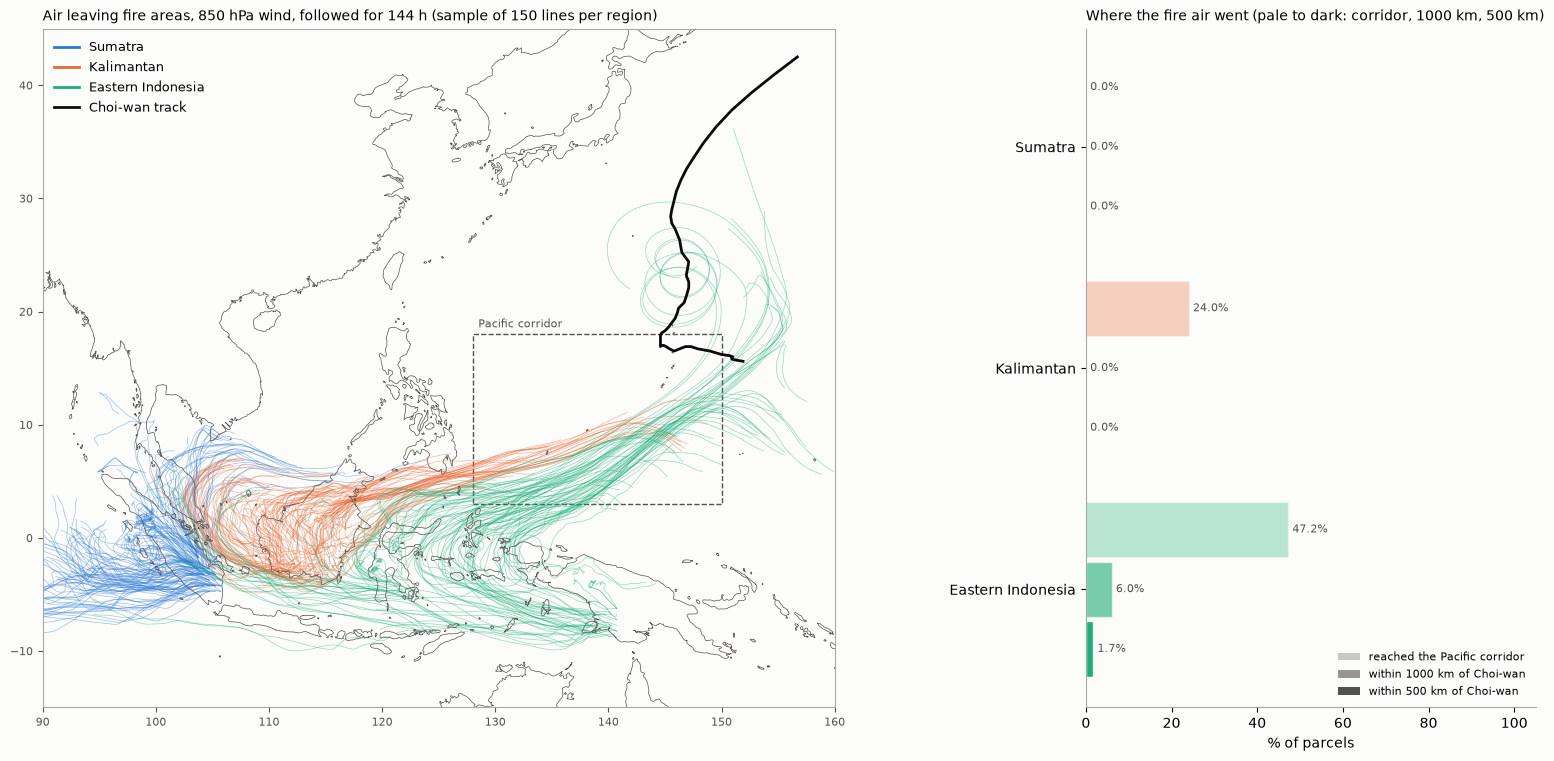

In [5]:
lev = MAP_LEVEL
lat, lon = fwd[lev]
res = fwd_res[fwd_res["level"] == lev].reset_index(drop=True)
rng = np.random.default_rng(1)
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [2.2, 1]}, constrained_layout=True)
ax = axes[0]
for name in REGIONS:
    idx = np.flatnonzero(res["region"] == name)
    pick = rng.choice(idx, size=min(LINES_PER_REGION, len(idx)), replace=False)
    for p in pick:
        ax.plot(lon[:, p], lat[:, p], color=REGION_COLORS[name], lw=0.5, alpha=0.45)
    ax.plot([], [], color=REGION_COLORS[name], lw=2, label=name)
ax.plot(track["LON"], track["LAT"], color="#0b0b0b", lw=2, label="Choi-wan track")
ax.add_patch(plt.Rectangle((CORRIDOR[0], CORRIDOR[2]), CORRIDOR[1] - CORRIDOR[0], CORRIDOR[3] - CORRIDOR[2], fill=False, ls="--", lw=1, ec="#52514e"))
ax.text(CORRIDOR[0] + 0.5, CORRIDOR[3] + 0.6, "Pacific corridor", fontsize=8, color="#52514e")
draw_base(ax)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title(f"Air leaving fire areas, {lev} wind, followed for {FWD_HOURS} h (sample of {LINES_PER_REGION} lines per region)", loc="left", fontsize=10)
ax = axes[1]
sub = share[share["level"] == lev].set_index("region").loc[list(REGIONS)]
y = np.arange(len(sub))
bars = [("corridor_pct", "reached the Pacific corridor", 0.3, -0.27), ("outer_pct", f"within {OUTER_STORM_KM} km of Choi-wan", 0.6, 0.0), ("storm_pct", f"within {NEAR_STORM_KM} km of Choi-wan", 1.0, 0.27)]
for col, label, alpha, off in bars:
    ax.barh(y + off, sub[col], height=0.25, color=[REGION_COLORS[r] for r in sub.index], alpha=alpha, edgecolor="#fcfcfb")
    ax.barh([np.nan], [np.nan], color="#52514e", alpha=alpha, label=label)
    for k in range(len(sub)):
        ax.text(sub[col].iloc[k] + 1, k + off, f"{sub[col].iloc[k]:.1f}%", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y)
ax.set_yticklabels(sub.index)
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_xlabel("% of parcels")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Where the fire air went (pale to dark: corridor, 1000 km, 500 km)", loc="left", fontsize=10)
fig.savefig(FIG_DIR / "trajectories_forward.png", dpi=110)
plt.show()

## Section 4: backward from Kuala Lumpur and Singapore

Every 3 hours, five parcels arrive at each city (the city and four points around it). Each is followed 72 hours back. The parcel is credited to the fire region whose **fire cells** (Section 3, any day of the window) it spent the most hours over; "No fire region" means it did not pass over any fire cell (for example air from the Indian Ocean or the South China Sea). Fire cells only count on Indonesian land, so the cities' own surroundings do not count as a fire region.

In [6]:
arrivals = pd.date_range(BWD_START, BWD_END, freq=f"{BWD_EVERY_H}h")
offsets = [(0, 0), (BWD_SPREAD, 0), (-BWD_SPREAD, 0), (0, BWD_SPREAD), (0, -BWD_SPREAD)]
bwd_rows = []
bwd = {}
for city, (clat, clon) in CITIES.items():
    a_t = np.repeat(arrivals, len(offsets))
    a_lat = np.tile([clat + o[0] for o in offsets], len(arrivals))
    a_lon = np.tile([clon + o[1] for o in offsets], len(arrivals))
    a_h = (a_t - T0).total_seconds().values / 3600
    for lev in LEVELS:
        lat, lon, sh = run_trajectories(lev, a_h, a_lat, a_lon, BWD_HOURS, -1)
        c_lat = (np.floor(lat / FIRE_CELL_DEG) + 0.5) * FIRE_CELL_DEG
        c_lon = (np.floor(lon / FIRE_CELL_DEG) + 0.5) * FIRE_CELL_DEG
        reg = np.vectorize(lambda a, b: FIRE_CELL_REGION.get((a, b), ""), otypes=[object])(c_lat, c_lon)
        hrs = pd.DataFrame({name: (reg == name).sum(axis=0) * DT_MIN / 60 for name in REGIONS})
        origin = hrs.idxmax(axis=1).where(hrs.max(axis=1) > 0, "No fire region")
        res = pd.DataFrame({"city": city, "level": lev, "arrival": a_t, "origin": origin.values})
        for name in REGIONS:
            res[f"hours_over_{name}"] = hrs[name].values
        bwd_rows.append(res)
        bwd[(city, lev)] = (lat, lon)
bwd_res = pd.concat(bwd_rows, ignore_index=True)
bwd_res.to_csv(OUT_DIR / "trajectories_backward.csv", index=False)
origin_share = (bwd_res.groupby(["city", "level"])["origin"].value_counts(normalize=True) * 100).round(1).unstack("origin").fillna(0)
print(f"Where the air arriving in each city came from (% of parcels, last {BWD_HOURS} h):")
print(origin_share.to_string())

Where the air arriving in each city came from (% of parcels, last 72 h):
origin                Kalimantan  No fire region  Sumatra
city         level                                       
Kuala Lumpur 10 m            0.0            97.5      2.5
             700 hPa        11.4            84.6      3.9
             850 hPa         8.2            21.8     70.0
Singapore    10 m           51.4            45.4      3.2
             700 hPa        19.6            77.1      3.2
             850 hPa        33.2            12.5     54.3


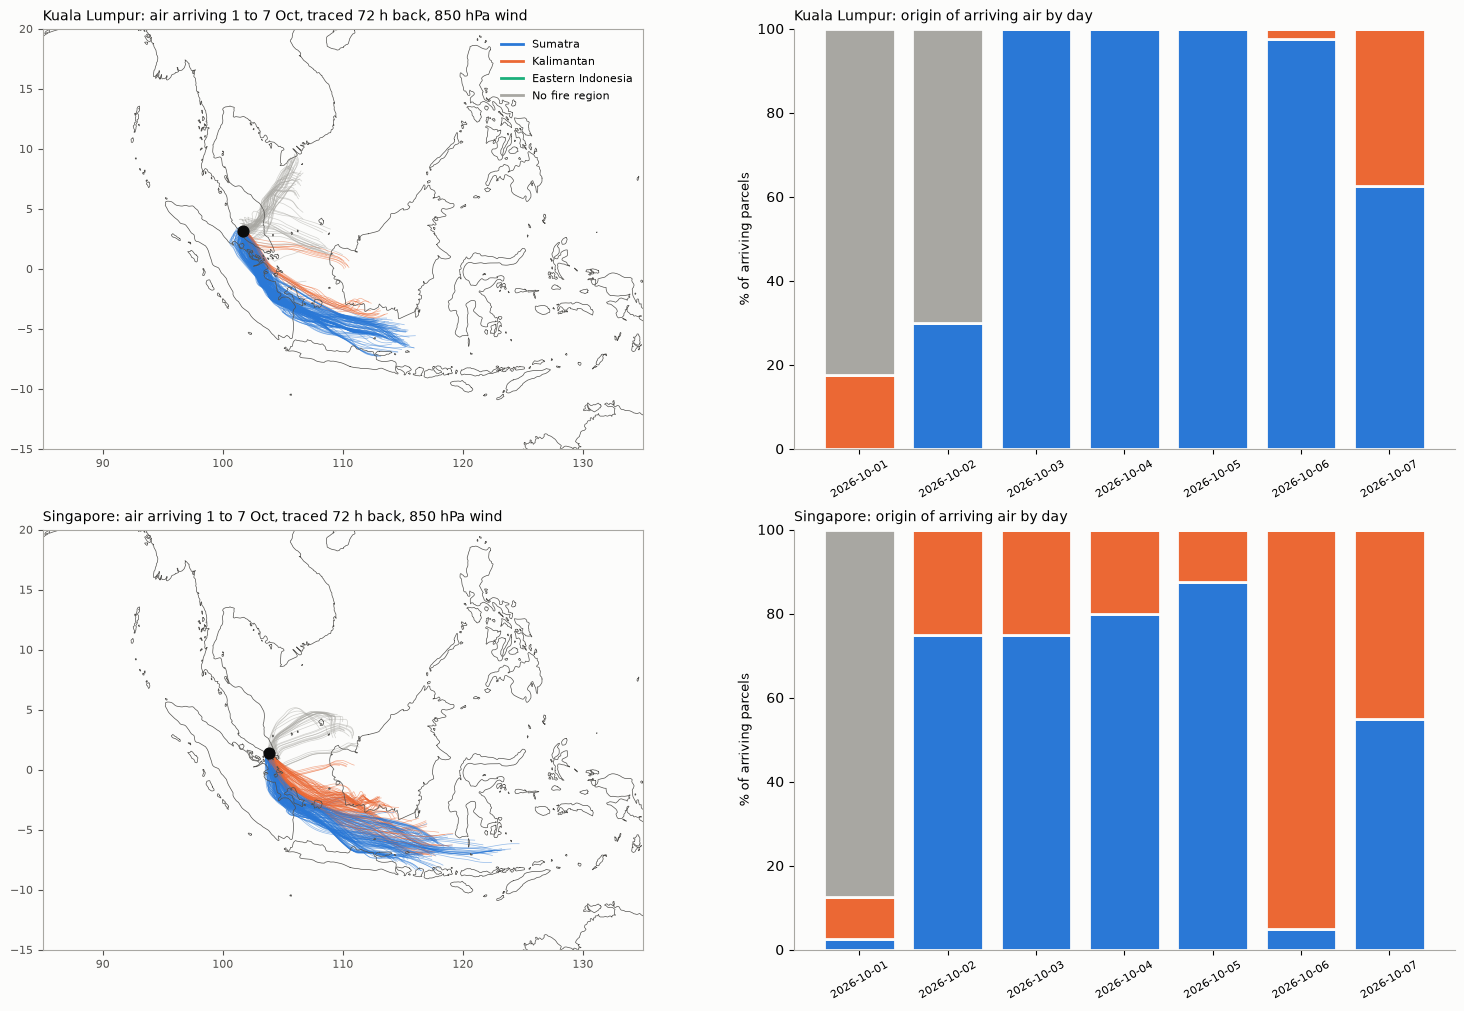

In [7]:
lev = MAP_LEVEL
order = list(REGIONS) + ["No fire region"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [1.15, 1]}, constrained_layout=True)
for row, city in enumerate(CITIES):
    lat, lon = bwd[(city, lev)]
    res = bwd_res[(bwd_res["city"] == city) & (bwd_res["level"] == lev)].reset_index(drop=True)
    ax = axes[row, 0]
    for p in range(lat.shape[1]):
        ax.plot(lon[:, p], lat[:, p], color=REGION_COLORS[res["origin"].iloc[p]], lw=0.5, alpha=0.5)
    for name in order:
        ax.plot([], [], color=REGION_COLORS[name], lw=2, label=name)
    ax.scatter([CITIES[city][1]], [CITIES[city][0]], s=60, color="#0b0b0b", zorder=5)
    draw_base(ax, (85.0, 135.0, -15.0, 20.0))
    ax.set_title(f"{city}: air arriving 1 to 7 Oct, traced {BWD_HOURS} h back, {lev} wind", loc="left", fontsize=10)
    if row == 0:
        ax.legend(frameon=False, fontsize=8, loc="upper right")
    ax = axes[row, 1]
    daily = res.assign(day=res["arrival"].dt.normalize()).groupby("day")["origin"].value_counts(normalize=True).unstack("origin").reindex(columns=order).fillna(0) * 100
    bottom = np.zeros(len(daily))
    for name in order:
        ax.bar(daily.index, daily[name], bottom=bottom, color=REGION_COLORS[name], edgecolor="#fcfcfb", linewidth=2, width=0.8, label=name)
        bottom = bottom + daily[name].values
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of arriving parcels", fontsize=9)
    ax.set_title(f"{city}: origin of arriving air by day", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
fig.savefig(FIG_DIR / "trajectories_backward.png", dpi=110)
plt.show()

___
**END**